# Light-Sheet smFRET Camera Simulation

*Note: Partially vibe-coded with Mistral GLM-3*

This notebook simulates **camera frames of fluorescence emission** from freely diffusing particles, as observed with a light-sheet microscope. It takes the particle-diffusion machinery of `1_Trajectory_Simulation.ipynb` (regular `pybromo` routine) and replaces the confocal PSF + TCSPC-timestamp detection with a **light-sheet PSF + camera**.

The light-sheet PSF is computed based on the [`psfmodels Light Sheet Notebook`](https://github.com/tlambert03/PSFmodels/blob/main/notebooks/lightsheet.ipynb) via the `psfmodels` module and wrapped in the class `LightSheetPSF` (`lightsheet_psf.py`), which implements the pybromo PSF interface (`eval`, `eval_xz`, `hash`, `to_hdf5`).

The model is simple as possible:

1. **Excitation** via a Gaussian-shaped lightsheet which is thin in $z$ and uniform in $x/y$. The light sheet is a 'sheet' of excitation perpendicular to the sample plane imaged by the camera. For a sheet formed by a low-NA Gaussian beam, the $1/e^2$ intensity waist is $w_0 = \lambda_{ex} / (\pi\,\mathrm{NA}_{sheet})$, so the excitation intensity at particle height $z$ is

$$I_{exc}(z) = \exp\left(-2\,(z/w_0)^2\right)$$

2. **Detection**: the "widefield"/light sheet PSF of the detection objective (via Gibson–Lanni model, `psfmodels.make_psf`), evaluated on a $z$ stack so that particles away from the focal plane form **broadened, dimmer** camera spots, with the photon number conserved per $z$ plane.

3. **Effective PSF**: the product $I_{exc}(z) \cdot PSF_{det}(x, y, z)$, precomputed on a 3D grid and linearly interpolated (`eval`).

4. **Camera frames**: for each 50 ms frame, the expected photon counts of each particle (modulated by the sheet profile at its $z$ position) are binned on the camera pixel grid per $z$ plane, convolved with the effective PSF at that defocus, and Poisson-sampled into integer pixel counts.

In [1]:
%matplotlib inline
import numpy as np
import tables
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import imageio.v3 as iio
import pybromo as pbm
import psfmodels
from lightsheet_psf import LightSheetPSF

print('Numpy version:', np.__version__)
print('PyTables version:', tables.__version__)
print('PyBroMo version:', pbm.__version__)
print('psfmodels version:', psfmodels.__version__)

Numpy version: 1.26.4
PyTables version: 3.9.2
PyBroMo version: 0.8.1
psfmodels version: 0.3.3


## 1. The light-sheet PSF

`LightSheetPSF` parameters:
   Parameter | Value | Meaning |
 |---|---|---|
 | `dxy` | 0.2 µm | lateral grid step = camera pixel size (sample space) |
 | `nx` | 51 | lateral grid size |
 | `dz`, `nz_half` | 0.25 µm, 24 | z grid spanning ±6 µm around focus |
 | `det_NA` | 0.8 | detection objective NA |
 | `em_wvl` | 0.58 µm | emission wavelength |
 | `ex_wvl`, `sheet_NA` | 0.520 µm, 0.08 | light-sheet excitation |
 | `ns` | 1.333 | sample refractive index |
 | `ni` | 1.333 | immersion medium RI, experimental value |
 | `ni0` | 1.333 | immersion medium RI, design value (objective corrected for this) |
 | `ng`, `ng0` | 1.333 | coverslip RI, experimental / design value |
 | `tg`, `tg0` | 170 µm | coverslip thickness, experimental / design value |

Notes on the refractive-index settings:

- `ni` vs `ni0` is the **immersion mismatch** the objective was built for
  (design) vs what is actually used — the dominant spherical-aberration term.
- `ns` is the **sample** RI. With a water-immersion objective the immersion
  and sample media are usually the same liquid, so in practice you set
  `ni = ns` (actual value) and keep `ni0` at the design value.
- Example: 20 % glycerol sample behind a water-design objective →
  `ns = ni = 1.359`, `ni0 = 1.333` (see the glycerol section).

In [2]:
ls_psf = LightSheetPSF(dxy=0.2, nx=51, dz=0.25, nz_half=24,
                        det_NA=1.46, em_wvl=0.58,
                        ex_wvl=0.520, sheet_NA=0.08,
                        # refractive indices (Gibson-Lanni model)
                        ns=1.333,    # sample RI
                        ni=1.518,    # immersion RI (experimental)
                        ni0=1.518,   # immersion RI (objective design value)
                        ng=1.333, ng0=1.333,   # coverslip RI (exp/design)
                        tg=170.0, tg0=170.0)   # coverslip thickness (exp/design)
print(ls_psf)
print('Sheet 1/e^2 waist w0: %.2f um' % ls_psf.sheet_waist)
print('PSF volume:', ls_psf.psf_volume.shape)
print('PSF hash:', ls_psf.hash()[:12])

# 20 % glycerol sample, water-immersion objective designed for n = 1.333:
# ls_psf = LightSheetPSF(..., ns=1.359, ni=1.359, ni0=1.333)

LightSheetPSF(dxy=0.2um, nx=51, dz=0.25um, nz_half=24, det_NA=1.46, em_wvl=0.58um, ex_wvl=0.52um, sheet_NA=0.08)
Sheet 1/e^2 waist w0: 2.07 um
PSF volume: (49, 51, 51)
PSF hash: 5c77c5e6299e


## 2. Light Sheet PSF Model

Before simulating camera data, the PSF is checked against the analytical expectations:

- **Lateral width**: the diffraction-limited detection PSF has an Airy-profile FWHM $\approx 0.51\,\lambda/\mathrm{NA}$ (fine 0.05 µm grid to avoid pixel-size bias)
- **Axial extent**: the effective light-sheet PSF must be confined in $z$ by the sheet, not by the detection depth of field
- **Photon conservation**: the sum-normalized detection kernels must conserve photon counts at every defocus
- **Defocus broadening**: the camera spot of a particle must broaden (and dim) away from focus

In [3]:
ls_fine = LightSheetPSF(dxy=0.05, nx=101, dz=0.25, nz_half=24)

def fwhm(profile, step):
    """ Lateral: in-focus detection PSF vs Airy FWHM 0.51*lam/NA """
    prof = profile / profile.max()
    idx = np.where(prof >= 0.5)[0]
    return (idx[-1] - idx[0] + 1) * step


k0 = ls_fine.detection_kernel(0.0)
lat_fwhm = fwhm(k0[k0.shape[0]//2], ls_fine.dxy)
airy_fwhm = 0.51 * ls_fine.em_wvl / ls_fine.det_NA
print(f"In-focus detection FWHM: {lat_fwhm:.3f} um   (Airy theory: {airy_fwhm:.3f} um)")

# Axial: effective PSF is confined by BOTH the sheet Gaussian and the
# detection depth of field; it must be narrower than either alone
zprof = ls_fine.psf_volume[:, ls_fine.nx//2, ls_fine.nx//2]
ax_fwhm = fwhm(zprof, ls_fine.dz)
det_z = ls_fine.detection_psf[:, ls_fine.nx//2, ls_fine.nx//2]
det_ax_fwhm = fwhm(det_z, ls_fine.dz)
sheet_fwhm = 2 * np.sqrt(2*np.log(2)) * ls_fine.sheet_waist
print(f"Effective axial FWHM:     {ax_fwhm:.3f} um   (detection-only: {det_ax_fwhm:.3f} um, sheet-only: {sheet_fwhm:.3f} um)")
assert ax_fwhm < det_ax_fwhm and ax_fwhm < sheet_fwhm, "effective PSF must be narrower than both factors"
print("  -> narrower than both the detection DOF and the sheet alone, as expected")

# Photon conservation of the rendering: single particle at fixed positions
em_rate, t_step, n = 50e3, 1e-3, 200
print("\nPhoton conservation (particle at x=y=0, fixed z, 200 ms exposure):")
for z_fix in [0.0, 1e-6, 2e-6, 4e-6]:
    x = np.zeros((1, n)); y = np.zeros((1, n)); z = np.full((1, n), z_fix)
    img = ls_psf.render_frame_expected(x, y, z, em_rate=em_rate, t_step=t_step)
    expected = em_rate * t_step * n * ls_psf.excitation_weights(np.array([z_fix]))[0]
    print(f"  z = {z_fix*1e6:+.0f} um: expected {expected:8.1f} photons, rendered {img.sum():8.1f}")

# Defocus broadening of the camera spot
print("\nDefocus broadening (camera spot FWHM at 0.2 um pixels):")
for z_fix in [0.0, 1e-6, 2e-6]:
    z = np.full((1, n), z_fix)
    img = ls_psf.render_frame_expected(x, y, z, em_rate=em_rate, t_step=t_step)
    row = img[img.shape[0]//2]
    print(f"  z = {z_fix*1e6:+.0f} um: spot FWHM = {fwhm(row, 0.2):.2f} um, peak = {img.max():.0f} counts/px")

In-focus detection FWHM: 0.350 um   (Airy theory: 0.370 um)
Effective axial FWHM:     1.250 um   (detection-only: 1.750 um, sheet-only: 4.572 um)
  -> narrower than both the detection DOF and the sheet alone, as expected

Photon conservation (particle at x=y=0, fixed z, 200 ms exposure):
  z = +0 um: expected  10000.0 photons, rendered  10000.0
  z = +1 um: expected   6267.5 photons, rendered   6267.5
  z = +2 um: expected   1543.1 photons, rendered   1543.1
  z = +4 um: expected      5.7 photons, rendered      5.7

Defocus broadening (camera spot FWHM at 0.2 um pixels):
  z = +0 um: spot FWHM = 0.20 um, peak = 2725 counts/px
  z = +1 um: spot FWHM = 1.80 um, peak = 62 counts/px
  z = +2 um: spot FWHM = 5.80 um, peak = 2 counts/px


### Visualizing the PSF

In [4]:
def ortho_views(volume, suptitle, x_um, y_um, z_um, gamma=0.2, filename=None):
    """Plot three orthographic views of a (z, y, x) volume.

    For centered volumes (detection / effective PSF) slices are used:
    the XY max over z would collapse the centered blob stack to a dot,
    and slices show the actual camera-image cross-sections.
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
    nrm = PowerNorm(gamma=gamma)
    iy0 = np.argmin(np.abs(np.asarray(y_um)))   # index of y = 0
    ix0 = np.argmin(np.abs(np.asarray(x_um)))   # index of x = 0
    iz0 = np.argmin(np.abs(np.asarray(z_um)))   # index of z = 0

    # XY: slice at z = 0 -> (ny, nx): what a focused molecule looks like on camera
    im0 = axes[0].imshow(volume[iz0],
                         extent=[x_um[0], x_um[-1], y_um[0], y_um[-1]],
                         origin='lower', cmap='inferno', aspect='equal', norm=nrm)
    axes[0].set_title('XY (slice at z = 0)\nCAMERA VIEW: image of a focused molecule')
    axes[0].set_xlabel('x (um)'); axes[0].set_ylabel('y (um)')
    plt.colorbar(im0, ax=axes[0], shrink=0.7)

    # XZ: slice at y = 0 -> (nz, nx): front view of the defocus cone
    im1 = axes[1].imshow(volume[:, iy0, :],
                         extent=[x_um[0], x_um[-1], z_um[0], z_um[-1]],
                         origin='lower', cmap='inferno', aspect='equal', norm=nrm)
    axes[1].set_title('XZ (slice at y = 0)\nfront view: defocus cone')
    axes[1].set_xlabel('x (um)'); axes[1].set_ylabel('z (um)')
    plt.colorbar(im1, ax=axes[1], shrink=0.7)

    # YZ: slice at x = 0 -> (nz, ny): side view of the defocus cone
    im2 = axes[2].imshow(volume[:, :, ix0],
                         extent=[y_um[0], y_um[-1], z_um[0], z_um[-1]],
                         origin='lower', cmap='inferno', aspect='equal', norm=nrm)
    axes[2].set_title('YZ (slice at x = 0)\nside view: defocus cone')
    axes[2].set_xlabel('y (um)'); axes[2].set_ylabel('z (um)')
    plt.colorbar(im2, ax=axes[2], shrink=0.7)

    fig.suptitle(suptitle, fontsize=13)
    if filename:
        fig.savefig(filename, dpi=150, bbox_inches='tight');

### Excitation PSF 
The excitation PSF is the light distribution driving fluorescence: only molecules inside it emit (bright = strong excitation, dim = weak, dark = none).
The light sheet is thin in z (~2 µm waist) and extended in x-y, so in the XY view (camera direction) it is a large uniform field, while the XZ/YZ views show the thin slab. In this model the sheet is uniform in x and y (its footprint covers the whole field of view), so only the z position matters — a molecule's brightness is modulated by this profile at its z.

Sheet thickness: w(y=0) = 2.07 um, w(y=12.8 um) = 2.31 um (+12% divergence at ROI edge)
V_exc shape: (81, 501, 501) == (nz, ny, nx) of the wide grids: (81, 501, 501)


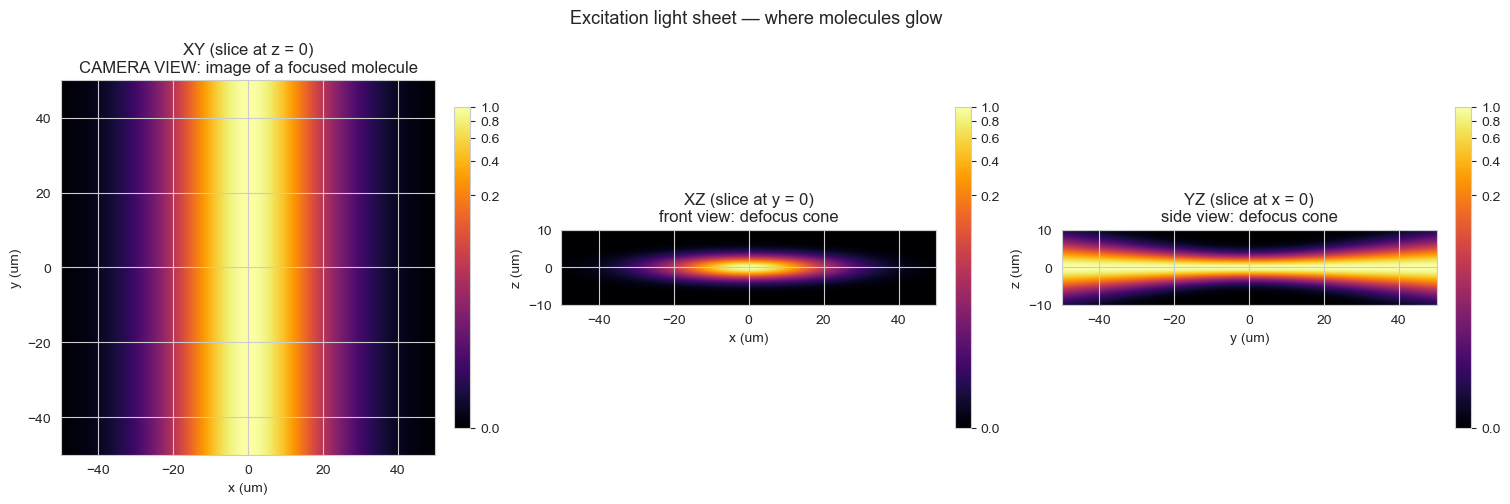

In [5]:
# Full 3D excitation volume of a Gaussian-beam light sheet:
# - thin Gaussian in z with waist w0 (set by sheet NA)
# - propagates along y: thickness w(y) = w0 * sqrt(1 + (y/zR)^2), zR = pi*w0^2/lambda
# - finite Gaussian footprint in x (unfocused direction of the sheet optics), width w_lat
exc_x_um = np.arange(-50, 50.01, 0.2)     # +-15 um along the sheet
exc_y_um = np.arange(-50, 50.01, 0.2)     # +-15 um propagation direction
exc_z_um = np.arange(-10, 10.01, 0.25)    # +-10 um across the sheet

zR = np.pi * ls_psf.sheet_waist**2 / ls_psf.ex_wvl       # Rayleigh range (~24 um)
w_lat = 15.0                                             # sheet footprint in x (um)

# BUILD THE VOLUME ON THE SAME WIDE GRIDS IT WILL BE PLOTTED WITH
X = exc_x_um[None, None, :]      # (1, 1, nx)
Y = exc_y_um[None, :, None]      # (1, ny, 1)
Z = exc_z_um[:, None, None]      # (nz, 1, 1)

w_y = ls_psf.sheet_waist * np.sqrt(1 + (Y / zR)**2)      # sheet half-thickness at each y
V_exc = (np.exp(-2 * (Z / w_y)**2)          # thin Gaussian slab, thickness varies with y
         * np.exp(-2 * (X / w_lat)**2))     # finite footprint along the sheet
print(f'Sheet thickness: w(y=0) = {ls_psf.sheet_waist:.2f} um, '
      f'w(y=12.8 um) = {ls_psf.sheet_waist*np.sqrt(1+(12.8/zR)**2):.2f} um '
      f'(+{np.sqrt(1+(12.8/zR)**2)*100-100:.0f}% divergence at ROI edge)')
print('V_exc shape:', V_exc.shape,   # must be (len(exc_z_um), len(exc_y_um), len(exc_x_um)) = (81, 151, 151)
      '== (nz, ny, nx) of the wide grids:', (len(exc_z_um), len(exc_y_um), len(exc_x_um)))

ortho_views(V_exc, 'Excitation light sheet — where molecules glow',
            exc_x_um, exc_y_um, exc_z_um)

#### Detection PSF — the signature of a point
The detection PSF is the image the system forms of an infinitesimally small
molecule ("point source"). The volume is shown for a molecule at the origin,
but the system is shift-invariant: a molecule at (x, y, z) produces the *same*
signature, just centered at its own (x, y) and taken at its own z-slice
(in focus = the central Airy spot; defocused = the wider cone slice).

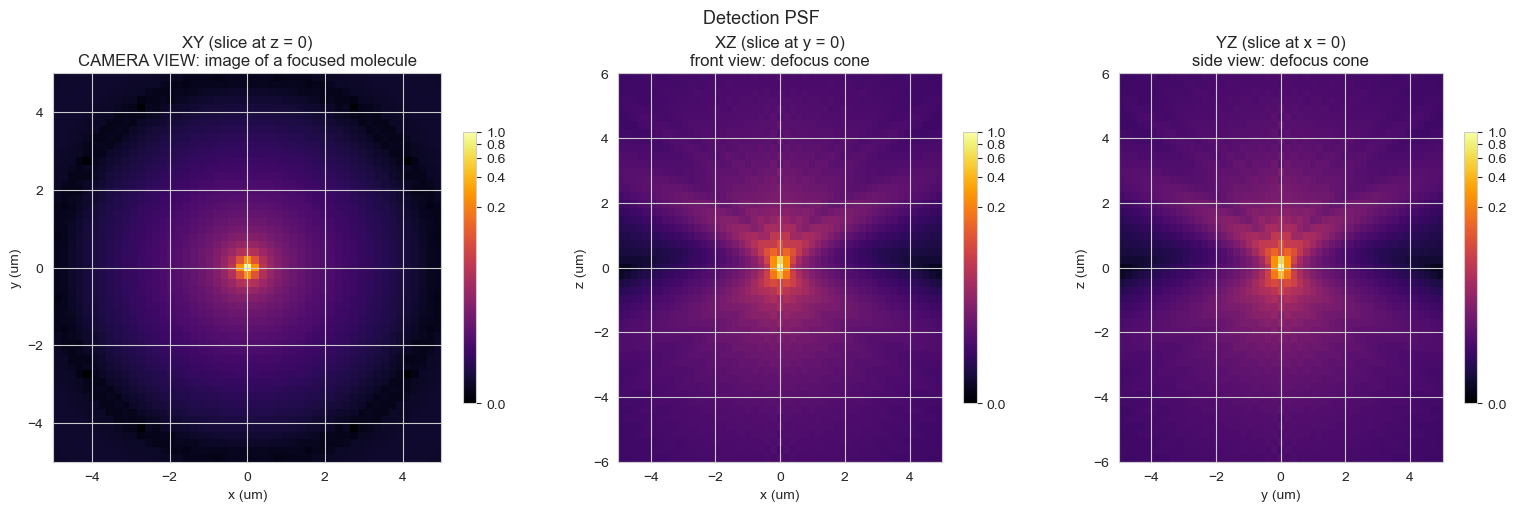

In [6]:
# 2) Detection PSF: signature (image) of an infinitesimally small molecule
#    as seen by the imaging system.
ortho_views(ls_psf.detection_psf,
            'Detection PSF',
            ls_psf.x_um, ls_psf.y_um, ls_psf.z_um)

### Effectove PSF
The effective PSF is the product of the excitation and detection PSFs. A molecule must *both* be excited and positioned near the focus to be imaged and land on the image sensor. The sheet and focus coincide here at $z = 0$. The effective PSF and the emission rate determine how many photons can be detected from each molecule while diffusing through the excitation/detection PSF.

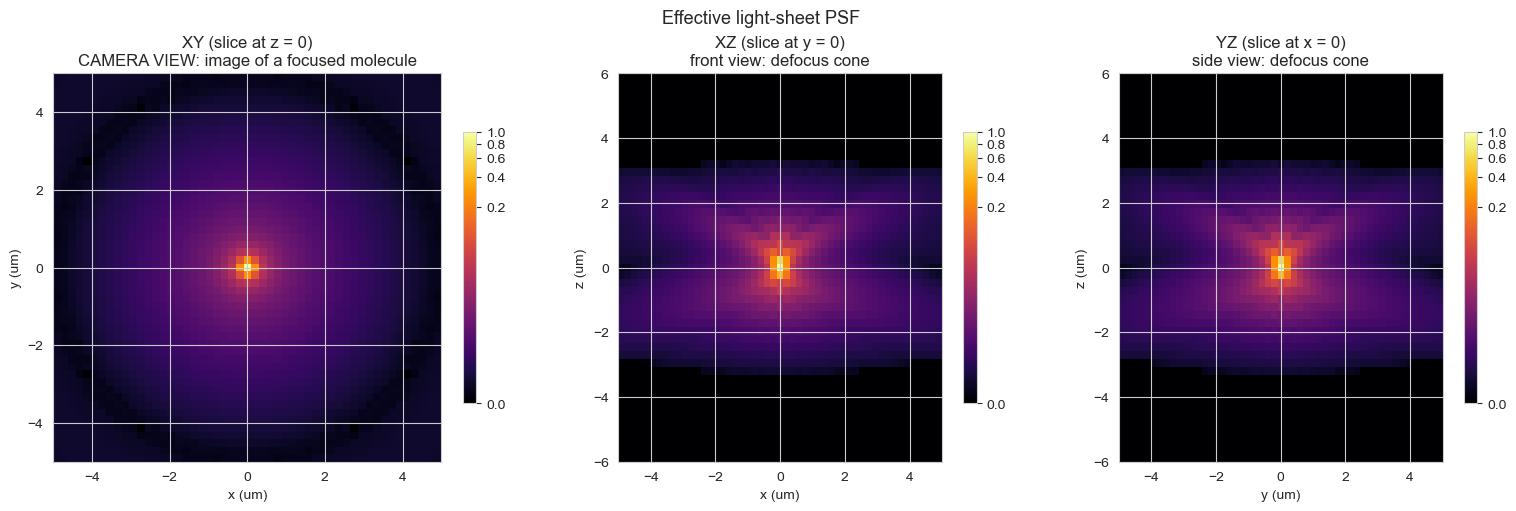

In [7]:
# 3) Effective PSF: excitation x detection
ortho_views(ls_psf.psf_volume,
            'Effective light-sheet PSF',
            ls_psf.x_um, ls_psf.y_um, ls_psf.z_um)

## 3. Particle diffusion simulation (pybromo, camera parameters)

Simulating with a 20 x objective with a ~50 x 50 µm FOV.

We are simulating two cases (same code, just with adapted parameters and run twice):

- ~ 30 bp DNA, labeled with ATTO 550, excited with 532 nm
    - In water -> D = 80 µm2/s
    - In 20 % glycerol -> 40 µm2/s

 We ignore aberations of the light sheet in water vs. 20 % glycerol for now.

Camera-system simulation parameters:

| Parameter | Value |
|---|---|
| Simulation duration | 200 s |
| Simulation time step | 1 ms |
| Camera frame integration time | 50 ms (50 steps/frame) |
| Diffusion coefficient | 10 µm²/s |
| Particles | 15 |
| Simulation box | 25.6 × 25.6 × 16 µm³ (= 128 × 128 px at 0.2 µm/px) |

In [8]:
rs = np.random.RandomState()
print('Initial random state:', pbm.hashfunc(rs.get_state()))

# --- Imaging system ---
magnification = 60.0                     # objective magnification
tube_lens = 164e-3                       # tube lens focal length (m)
f_objective = tube_lens / magnification  # objective focal length (m)
lens_na = 1.46

# Camera: Allied Vision U1800, 2.25 um pixels
camera_pixel = 3.45E-6                   # sensor pixel size (m)
pixel_size = camera_pixel / magnification  # camera pixel in sample space (m)
fov_camera = 50e-6                       # desired field of view (m)
roi = int(np.floor(fov_camera / pixel_size))

print(f'Objective focal length: {f_objective*1e3:.1f} mm')
print(f'Camera pixel in sample space: {pixel_size*1e6:.4f} um')
print(f'ROI: {roi} x {roi} px = {roi*pixel_size*1e6:.2f} x {roi*pixel_size*1e6:.2f} um FOV')

# --- Light-sheet PSF, derived from the camera variables ---
# dxy = the camera pixel in sample space, so the PSF grid IS the camera grid
# and the rendering kernel is sampled exactly at the pixel pitch.
ls_psf = LightSheetPSF(
    dxy=pixel_size * 1e6,        # lateral grid step (um) = camera pixel in sample space
    nx=121,                       # kernel support: 51 * 0.1125 um = 5.7 um
    dz=0.1, nz_half=60,         # z grid: +-6 um around the sheet/focus
    det_NA=lens_na,                  # detection objective NA
    em_wvl=0.58,                 # emission wavelength (um)
    ex_wvl=0.532,                # excitation wavelength (um)
    sheet_NA=0.08,               # light-sheet NA -> w0 = ex_wvl/(pi*NA) um
    # immersion / sample refractive indices (Gibson-Lanni)
    ns=1.333, ni=1.518, ni0=1.518,
    ng=1.515, ng0=1.515, tg=170.0, tg0=170.0,
    sheet_extent_x = 30.0, sheet_extent_y = np.inf
)

print(ls_psf)
print('Sheet 1/e^2 waist w0: %.2f um' % ls_psf.sheet_waist)
print('PSF volume:', ls_psf.psf_volume.shape)
print('PSF hash:', ls_psf.hash()[:12])
print(f'Airy FWHM: {0.51 * ls_psf.em_wvl / ls_psf.det_NA:.2f} um '
      f'= {0.51 * ls_psf.em_wvl / ls_psf.det_NA / ls_psf.dxy:.1f} camera pixels')

t_step = 1E-3 # Simulation step size
t_max = 0.5 # simulation time
frame_steps = 4 # Camera frame integration time, 50 steps = 50 ms
frame_time = frame_steps * t_step
n_frames = int(t_max / frame_time)
print(f"Number of frames: {n_frames}")

# Particle simulation
box = pbm.Box(x1=-roi/2*pixel_size, x2=roi/2*pixel_size,
              y1=-roi/2*pixel_size, y2=roi/2*pixel_size,
              z1=-8e-6, z2=8e-6)
Du = 80            # um^2 / s
D1 = Du*(1e-6)**2    # m^2 / s
n_particles = 50
P = pbm.Particles.from_specs(num_particles=(n_particles,), D=(D1,), box=box, rs=rs)

S = pbm.ParticlesSimulation(t_step=t_step, t_max=t_max, particles=P, box=box, psf=ls_psf)
print(S)
S.print_sizes()

Initial random state: 41b14f503a0132255ef643532850f8e7a4b842b5
Objective focal length: 2.7 mm
Camera pixel in sample space: 0.0575 um
ROI: 869 x 869 px = 49.97 x 49.97 um FOV
LightSheetPSF(dxy=0.057499999999999996um, nx=121, dz=0.1um, nz_half=60, det_NA=1.46, em_wvl=0.58um, ex_wvl=0.532um, sheet_NA=0.08)
Sheet 1/e^2 waist w0: 2.12 um
PSF volume: (121, 121, 121)
PSF hash: 9f21f6174789
Airy FWHM: 0.20 um = 3.5 camera pixels
Number of frames: 125
Box: X 50.0um, Y 50.0um, Z 16.0um
#Particles: 50 D: 8e-11, 2.1 pM, t_step 1000.0us, t_max 0.5s ID_EID 0 0
  Number of particles: 50
  Number of time steps: 500
  Emission array - 1 particle (float32): 0.0 MB
  Emission array (float32): 0.1 MB
  Position array (float32): 0.3 MB 


In [9]:
# --- Run the particle diffusion simulation ---
S.simulate_diffusion(
    total_emission=False,      # per-particle emission (we render camera frames later)
    save_pos=True,             # store trajectories for the camera rendering
    rs=rs,                     # the RandomState from the setup cell
    chunksize=2**21,           # 1M samples per chunk on disk
    chunkslice='times',        # chunk along the time axis (good for our access pattern)
    verbose=True               # progress print every ~few seconds of sim time
)

- Start trajectories simulation - Wed Oct 28 16:42:58 2026
[PID 32756] Diffusion time: 2097s
- End trajectories simulation - Wed Oct 28 16:43:00 2026


## 4. Camera frames from the PSF convolution

For each X ms frame:

1. **Excitation weighting**: each particle's emission is modulated by the light-sheet profile at its $z$ position — particles outside the sheet go dark
2. **Pixel binning per z plane**: expected photon counts are binned on the 128 × 128 camera grid, grouped by $z$ plane
3. **PSF convolution**: each $z$ slice is convolved with the sum-normalized detection kernel at that defocus — in-focus particles form diffraction-limited spots, defocused ones broad, dim spots
4. **Shot noise**: Poisson sampling yields integer photon counts per pixel (uint16)

Emission rate: 50 kcps per particle at the sheet center; camera background: 10 cps/pixel.

In [10]:
# Determining the emission rate
# Excitation intensity -> Absorption -> Emission -> Detection
# Dye photophysics
excitation_wvl = 532E-9
emission_wvl = 580E-9
qy = 0.8
tau = 4E-9

ext_coef = 1.45E5 # M-1 cm-1
sigma_abs = np.log(10) * ext_coef * 1e3 / 6.022E23 * 1e-4   # Absorption cross section m^2
E_ph = 6.626E-34 * 3E8 / excitation_wvl # Photon energy in J

# Illumination intensity of the light sheet
sheet_intensity = 1E7 # W/m^2
I_sat = E_ph / (sigma_abs * tau) # saturation intensity
saturation = sheet_intensity / I_sat

# Emission rate:
emitted_rate = (qy / tau) * saturation / (1 + saturation)

# Detection: Objective collection + camera quantum efficiency
sin_theta = lens_na / 1.518
collection_fraction = (1 - np.sqrt(1 - sin_theta**2)) / 2
optics_transmission = 0.5
camera_qe = 0.6
detection_efficiency = collection_fraction * optics_transmission * camera_qe

# Detected photon rate
em_rate = emitted_rate * detection_efficiency


print(f'ATTO550 at {excitation_wvl*1e9:.0f} nm:')
print(f'  absorption cross-section: {sigma_abs:.2e} m^2')
print(f'  saturation intensity:     {I_sat/1e4/1e3:.0f} kW/cm^2')
print(f'  sheet intensity:          {sheet_intensity/1e4/1e3:.0f} kW/cm^2  (S = {saturation:.2f})')
print(f'  emitted rate:             {emitted_rate/1e3:.1f} kcps  (ceiling: {qy/tau/1e3:.0f} kcps)')
print(f'  detection efficiency:     {detection_efficiency*100:.2f}%  '
      f'(collection {collection_fraction*100:.1f}% of 4pi, T={optics_transmission}, QE={camera_qe})')
print(f'  DETECTED em_rate:         {em_rate:.0f} photons/s per molecule at sheet center')

ATTO550 at 532 nm:
  absorption cross-section: 5.54e-20 m^2
  saturation intensity:     168 kW/cm^2
  sheet intensity:          1 kW/cm^2  (S = 0.01)
  emitted rate:             1180.1 kcps  (ceiling: 200000 kcps)
  detection efficiency:     10.89%  (collection 36.3% of 4pi, T=0.5, QE=0.6)
  DETECTED em_rate:         128546 photons/s per molecule at sheet center


In [ ]:
positions = S.position[:]   # (num_particles, 3, n_samples)
print('Positions array:', positions.shape)
print('Samples:', positions.shape[-1], '-> frames:', positions.shape[-1] // frame_steps)

background_rate = 10  # photons/s/pixel

frames = ls_psf.render_camera_frames(
    positions,
    t_step=t_step,
    frame_steps=frame_steps,
    em_rate=em_rate,
    roi=roi,
    pixel_size_m=pixel_size,
    background_rate=background_rate,
    rs=rs)
print('Camera frames:', frames.shape, frames.dtype)
print('Photons per frame (mean):', frames.sum(axis=(1, 2)).mean().round(1))

Positions array: (50, 3, 500)
Samples: 500 -> frames: 125


Quick look at the first six camera frames.

In [ ]:
gamma = 0.5

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(frames[i], cmap='inferno', norm=PowerNorm(gamma=gamma))
    ax.set_title(f'Frame {i} (t = {i*frame_time*1e3:.0f} ms)')
    ax.set_axis_off()
plt.tight_layout();

In [ ]:
# Projection of ALL 50 ms frames into one image ---
# Max-projection: the brightest value each pixel ever reached (best SNR per
# pixel, shows every molecule that was ever visible).
# Sum-projection: total counts (a 200 s exposure).
frame_max = frames.max(axis=0)
frame_sum = frames.sum(axis=0)

gamma = 0.8

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
im0 = axes[0].imshow(frame_max, cmap='inferno', norm=PowerNorm(gamma=gamma))
axes[0].set_title(f'Max-projection of all {frames.shape[0]} frames\n'
                  '(brightest value per pixel)')
fig.colorbar(im0, ax=axes[0], shrink=0.8, label='counts / pixel')

im1 = axes[1].imshow(frame_sum, cmap='inferno', norm=PowerNorm(gamma=gamma))
axes[1].set_title(f'Sum-projection of all {frames.shape[0]} frames\n'
                  f'(total counts over {t_max:.0f} s exposure)')
fig.colorbar(im1, ax=axes[1], shrink=0.8, label='total counts / pixel')
plt.tight_layout();

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t_frames = np.arange(frames.shape[0]) * frame_time
axes[0].plot(t_frames, frames.sum(axis=(1, 2)))
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('Counts / frame')
axes[0].set_title('Total counts per frame')

f_max = frames[0].max()
axes[1].hist(frames[0].ravel(), bins=50, range=(0, f_max))
axes[1].set_xlabel('Counts / pixel'); axes[1].set_ylabel('# Pixels')
axes[1].set_title('Pixel intensity histogram (frame 0)')
plt.tight_layout()
plt.show

## 5. Save the camera frames

The frame stack is saved as HDF5 with the acquisition parameters as attributes. The pybromo trajectory file already contains the light-sheet PSF (via `LightSheetPSF.to_hdf5`), so the simulation is fully traceable.


In [ ]:
sim_name = S.compact_name()
S.store.close()

filename = f'lightsheet_camera_{sim_name}.hdf5'
with tables.open_file(filename, 'w') as f:
    f.create_array('/', 'frames', obj=frames,
                   title='Simulated light-sheet camera frames (uint16)')
    for attr, value in [('frame_time', frame_time),
                        ('t_step', t_step),
                        ('pixel_size_m', pixel_size),
                        ('em_rate', em_rate),
                        ('background_rate', background_rate),
                        ('psf_hash', ls_psf.hash())]:
        f.set_node_attr(f.root, attr, value)
print('Saved:', filename)

In [ ]:
# --- Export the camera frames as a compressed 8-bit .mov (H.264)
# Rescale uint16 photon counts to 0-255 with ONE global factor
# (max of the whole stack -> 255), so intensities stay comparable
# across frames;

intensity_scale = 255.0 / frames.max()
frames_u8 = (frames.astype(np.float64) * intensity_scale).round().clip(0, 255).astype(np.uint8)

video_filename = f'lightsheet_camera_{sim_name}.mov'
iio.imwrite(video_filename, frames_u8, fps=int(round(1 / frame_time)),
            codec='libx264', quality=7, macro_block_size=1)
print('Saved:', video_filename)